# CelebA Faces

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import (layers, models, callbacks, utils, metrics, losses, optimizers)
from scipy.stats import norm
import pandas as pd
import os

2026-11-05 01:37:28.137151: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-05 01:37:28.258663: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-05 01:37:29.779257: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Parameters <a name="parameters"></a>

In [2]:
IMAGE_SIZE = 32
CHANNELS = 3
BATCH_SIZE = 128
NUM_FEATURES = 128
Z_DIM = 200
LEARNING_RATE = 0.0005
EPOCHS = 10
BETA = 2000

In [3]:
dataset_path = "img_align_celeba"

## 1. Prepare the data <a name="prepare"></a>

In [4]:
dataset = utils.image_dataset_from_directory(dataset_path, labels=None, color_mode="rgb", image_size=(IMAGE_SIZE, IMAGE_SIZE), batch_size=BATCH_SIZE, shuffle=True, seed=42, interpolation="bilinear")

Found 202599 files.


I0000 00:00:1793821066.499484   21843 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:01:00.0, compute capability: 8.9


In [5]:
def preprocess(img):

    return tf.cast(img, "float32") / 255.0

In [6]:
train = dataset.map(lambda x: preprocess(x))

In [14]:
train_sample = train.take(10).batch(10).get_single_element()[0].numpy()
print(train_sample.shape)
print(train_sample.dtype)

(128, 32, 32, 3)
float32


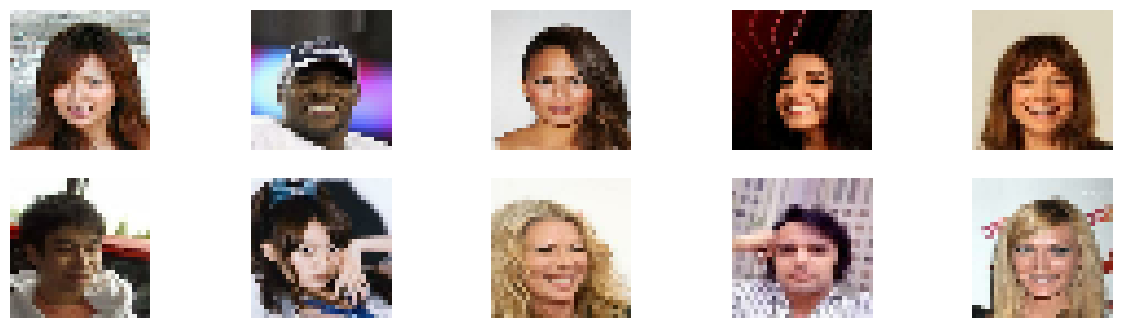

In [15]:
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_sample[i])
    plt.axis("off")

plt.show()

## 2. Build the variational autoencoder <a name="build"></a>

In [16]:
class Sampling(layers.Layer):

    def call(self, inputs):

        z_mean, z_log_var = inputs

        epsilon = tf.random.normal(shape=tf.shape(z_mean))

        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

In [17]:
# Encoder
encoder_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input")
x = layers.Conv2D(NUM_FEATURES, kernel_size=3, strides=2, padding="same")(encoder_input)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU()(x)

x = layers.Conv2D(NUM_FEATURES, kernel_size=3, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU()(x)

x = layers.Conv2D(NUM_FEATURES, kernel_size=3, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU()(x)

x = layers.Conv2D(NUM_FEATURES, kernel_size=3, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU()(x)

shape = x.shape[1:]

x = layers.Flatten()(x)
z_mean = layers.Dense(Z_DIM, name="z_mean")(x)
z_log_var = layers.Dense(Z_DIM, name="z_log_var")(x)
sampling = Sampling()
z = sampling([z_mean, z_log_var])

encoder = models.Model(encoder_input, [z_mean, z_log_var, z], name="encoder")

In [18]:
# Decoder
decoder_input = layers.Input(shape=(Z_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape)))(decoder_input)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU()(x)

x = layers.Reshape(shape)(x)
x = layers.Conv2DTranspose(NUM_FEATURES, kernel_size=3, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU()(x)

x = layers.Conv2DTranspose(NUM_FEATURES, kernel_size=3, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU()(x)

x = layers.Conv2DTranspose(NUM_FEATURES, kernel_size=3, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU()(x)

x = layers.Conv2DTranspose(NUM_FEATURES, kernel_size=3, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU()(x)

decoder_output = layers.Conv2DTranspose(CHANNELS, kernel_size=3, strides=1, activation="sigmoid", padding="same")(x)
decoder = models.Model(decoder_input, decoder_output)

In [19]:
class VAE(models.Model):

    def __init__(self, encoder, decoder, **kwargs):
        super(VAE, self).__init__(**kwargs)

        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]

    def call(self, inputs):
        
        z_mean, z_log_var, z = self.encoder(inputs)
        z_s = self.decoder(z)

        return z_mean, z_log_var, z_s

    def train_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:

            z_mean, z_log_var, reconstruction = self(data)
            reconstruction_loss = tf.reduce_mean(BETA * losses.binary_crossentropy(data, reconstruction, axis=(1, 2, 3)))
            kl_loss = tf.reduce_mean(tf.reduce_sum(-0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)), axis=1))
            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            m.name: m.result()
            for m in self.metrics
        }

    def test_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, reconstruction = self(data)

        reconstruction_loss = tf.reduce_mean(BETA * losses.binary_crossentropy(data, reconstruction, axis=(1, 2, 3)))

        kl_loss = tf.reduce_mean(tf.reduce_sum(-0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)), axis=1))

        total_loss = reconstruction_loss + kl_loss

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }
        

    def get_config(self):

        config = super().get_config()
    
        config.update({
            "encoder": tf.keras.utils.serialize_keras_object(self.encoder),
            "decoder": tf.keras.utils.serialize_keras_object(self.decoder)
        })
    
        return config

        
    @classmethod
    def from_config(cls, config):
        
        encoder = tf.keras.utils.deserialize_keras_object(config.pop("encoder"))
        decoder = tf.keras.utils.deserialize_keras_object(config.pop("decoder"))
    
        return cls(encoder=encoder, decoder=decoder, **config)

In [20]:
vae = VAE(encoder, decoder)

## 3. Train the variational autoencoder <a name="train"></a>

In [21]:
optimizer = optimizers.Adam(learning_rate=LEARNING_RATE)
vae.compile(optimizer=optimizer)
callback = callbacks.ModelCheckpoint(filepath="celebA.keras", save_weights_only=False, save_freq="epoch", monitor="loss", mode="min", save_best_only=True, verbose=1)

In [22]:
class ImageGenerator(callbacks.Callback):

    def __init__(self, num_img, latent_dim):
        super().__init__()
        self.num_img = num_img
        self.latent_dim = latent_dim

    def on_epoch_end(self, epoch, logs=None):

        # Generate random latent vectors
        latent_vectors = tf.random.normal((self.num_img, self.latent_dim))

        # Generate images using decoder
        images = self.model.decoder(latent_vectors) * 255

        # Save generated images
        for i, image in enumerate(images):
            utils.array_to_img(image).save(f"./face/generated_img_{epoch:03d}_{i}.png")


In [23]:
vae.fit(train, epochs=EPOCHS, callbacks=[callback, ImageGenerator(num_img=10, latent_dim=Z_DIM)])

Epoch 1/10


2026-11-05 01:54:38.919959: I external/local_xla/xla/service/service.cc:163] XLA service 0x7ff308088650 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-05 01:54:38.919985: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4060, Compute Capability 8.9
2026-11-05 01:54:39.047286: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-05 01:54:39.944400: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92600


   3/1583 ━━━━━━━━━━━━━━━━━━━━ 1:08 43ms/step - kl_loss: 0.0882 - reconstruction_loss: 1385.0854 - total_loss: 1385.1737  

I0000 00:00:1793822085.871373   21965 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1582/1583 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - kl_loss: 24.1269 - reconstruction_loss: 1133.8308 - total_loss: 1157.9575

2026-11-05 01:55:46.932016: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1953', 8 bytes spill stores, 8 bytes spill loads

2026-11-05 01:55:46.964295: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1963', 4 bytes spill stores, 4 bytes spill loads

2026-11-05 01:55:47.305054: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1', 120 bytes spill stores, 120 bytes spill loads

2026-11-05 01:55:47.319952: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 64 bytes spill stores, 64 bytes spill loads



1583/1583 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - kl_loss: 24.1294 - reconstruction_loss: 1133.8003 - total_loss: 1157.9296
Epoch 1: finished saving model to celebA.keras


/home/sadat/research/lib/python3.12/site-packages/keras/src/callbacks/model_checkpoint.py:276: UserWarning: Can save best model only with loss available.
  if self._should_save_model(epoch, batch, logs, filepath):


1583/1583 ━━━━━━━━━━━━━━━━━━━━ 76s 42ms/step - kl_loss: 28.1785 - reconstruction_loss: 1085.5104 - total_loss: 1113.6885
Epoch 2/10
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - kl_loss: 30.8135 - reconstruction_loss: 1048.5081 - total_loss: 1079.3215
Epoch 2: finished saving model to celebA.keras
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 62s 39ms/step - kl_loss: 31.0681 - reconstruction_loss: 1046.1418 - total_loss: 1077.2104
Epoch 3/10
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - kl_loss: 31.7607 - reconstruction_loss: 1042.0203 - total_loss: 1073.7813
Epoch 3: finished saving model to celebA.keras
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 83s 38ms/step - kl_loss: 32.0009 - reconstruction_loss: 1040.7706 - total_loss: 1072.7728
Epoch 4/10
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - kl_loss: 32.6791 - reconstruction_loss: 1038.4535 - total_loss: 1071.1333
Epoch 4: finished saving model to celebA.keras
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 62s 39ms/step - kl_loss: 32.8510 - reconstruction_loss: 1037.5648 - tota

In [24]:
# Save the final models
vae.save("celebA.keras")
encoder.save("celebA.encoder.keras")
decoder.save("celebA.decoder.keras")

## 3. Reconstruct using the variational autoencoder <a name="reconstruct"></a>

In [25]:
batches_to_predict = 1
example_images = np.array(list(train.take(batches_to_predict).get_single_element()))

In [26]:
z_mean, z_log_var, reconstructions = vae.predict(example_images)

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


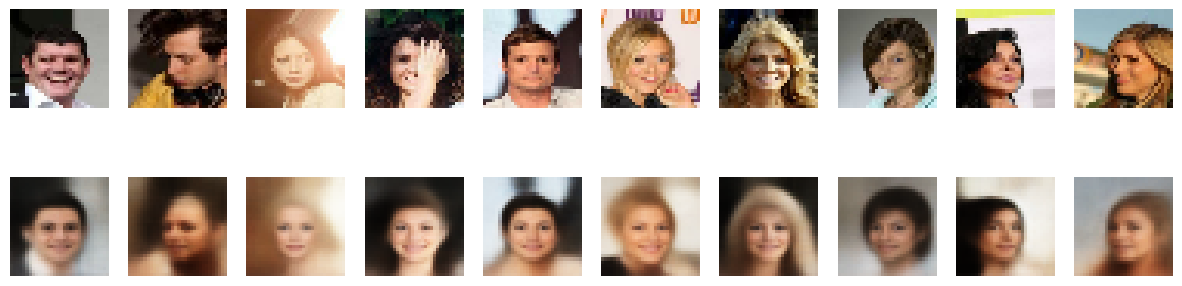

In [27]:
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(example_images[i])
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructions[i])
    plt.axis("off")

plt.show()

## 4. Latent space distribution

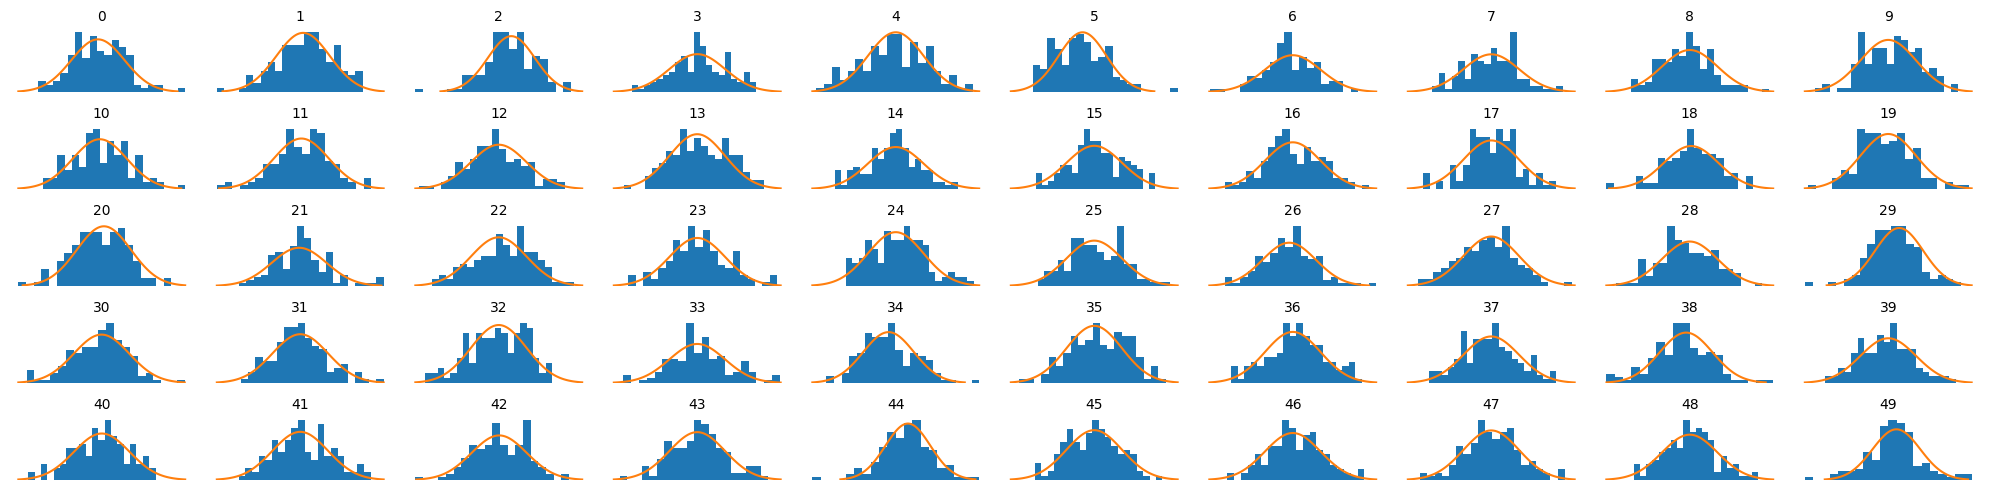

In [29]:
_, _, z = vae.encoder.predict(example_images, verbose=0)
x = np.linspace(-3, 3, 100)
fig = plt.figure(figsize=(20, 5))

for i in range(50):
    
    ax = fig.add_subplot(5, 10, i + 1)
    ax.hist(z[:, i], bins=20, density=True)
    ax.plot(x, norm.pdf(x))
    ax.set_title(str(i), fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Generate new faces <a name="decode"></a>

In [30]:
grid_width, grid_height = (10, 3)
z_sample = np.random.normal(size=(grid_width * grid_height, Z_DIM))

In [31]:
reconstructions = decoder.predict(z_sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


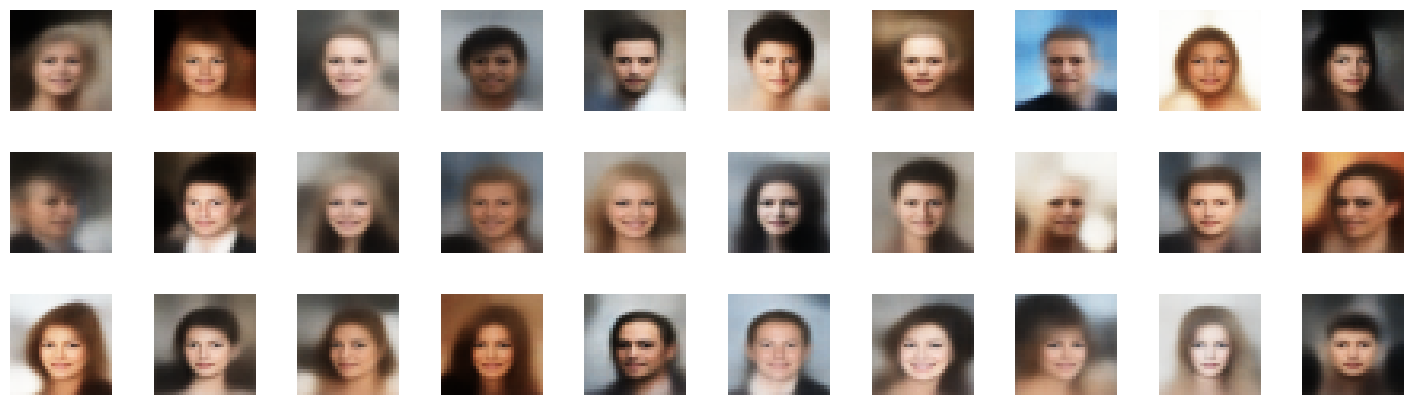

In [32]:
# Draw a plot of decoded images
fig = plt.figure(figsize=(18, 5))
fig.subplots_adjust(hspace=0.4, wspace=0.4)

# Output the grid of faces
for i in range(grid_width * grid_height):
    ax = fig.add_subplot(grid_height, grid_width, i + 1)
    ax.axis("off")
    ax.imshow(reconstructions[i, :, :])

## 6. Manipulate the images <a name="manipulate"></a>

In [33]:
attributes = pd.read_csv("list_attr_celeba.txt", sep=r"\s+", skiprows=1, header=0)
attributes.rename(columns={attributes.columns[0]: "image_id"}, inplace=True)
attributes.set_index("image_id", inplace=True)

In [34]:
LABEL = "Blond_Hair"
labelled_test = utils.image_dataset_from_directory("img_align_celeba", labels=attributes[LABEL].tolist(), color_mode="rgb", image_size=(IMAGE_SIZE, IMAGE_SIZE), batch_size=BATCH_SIZE, 
                                                   shuffle=True,seed=42, validation_split=0.2, subset="validation", interpolation="bilinear")

labelled = labelled_test.map(lambda x, y: (preprocess(x), y))

Found 202599 files belonging to 2 classes.
Using 40519 files for validation.


In [35]:
def get_vector_from_label(data, vae, embedding_dim, label):

    # Initialize positive and negative embeddings
    sum_POS = np.zeros(embedding_dim, dtype="float32")
    sum_NEG = np.zeros(embedding_dim, dtype="float32")

    mean_POS = np.zeros(embedding_dim, dtype="float32")
    mean_NEG = np.zeros(embedding_dim, dtype="float32")

    n_POS = 0
    n_NEG = 0
    current_dist = 0

    print(f"Label: {label}")
    print("Images : POS move : NEG move : Distance : Δ distance")

    while n_POS < 10000:

        # Get a batch of images and attributes
        images, attributes = list(data.take(1).get_single_element())

        # Extract latent embeddings
        _, _, z = vae.encoder.predict(np.array(images), verbose=0)

        # Separate positive and negative embeddings
        z_POS = z[attributes == 1]
        z_NEG = z[attributes == -1]

        # Update positive mean
        if len(z_POS) > 0:
            sum_POS += np.sum(z_POS, axis=0)
            n_POS += len(z_POS)

            new_mean_POS = sum_POS / n_POS
            movement_POS = np.linalg.norm(new_mean_POS - mean_POS)
        else:
            new_mean_POS = mean_POS
            movement_POS = 0

        # Update negative mean
        if len(z_NEG) > 0:
            sum_NEG += np.sum(z_NEG, axis=0)
            n_NEG += len(z_NEG)

            new_mean_NEG = sum_NEG / n_NEG
            movement_NEG = np.linalg.norm(new_mean_NEG - mean_NEG)
        else:
            new_mean_NEG = mean_NEG
            movement_NEG = 0

        # Calculate attribute direction
        vector = new_mean_POS - new_mean_NEG

        new_dist = np.linalg.norm(vector)
        dist_change = new_dist - current_dist

        print(
            f"{n_POS} : "
            f"{movement_POS:.3f} : "
            f"{movement_NEG:.3f} : "
            f"{new_dist:.3f} : "
            f"{dist_change:.3f}"
        )

        # Update previous values
        mean_POS = new_mean_POS.copy()
        mean_NEG = new_mean_NEG.copy()
        current_dist = new_dist

        # Check convergence
        if movement_POS + movement_NEG < 0.08:
            vector = vector / current_dist
            print(f"Found the {label} vector")
            break

    return vector

In [36]:
attribute_vec = get_vector_from_label(labelled, vae, Z_DIM, LABEL)

Label: Blond_Hair
Images : POS move : NEG move : Distance : Δ distance
22 : 3.200 : 1.413 : 3.744 : 3.744
44 : 2.081 : 0.929 : 2.921 : -0.823
65 : 1.169 : 0.567 : 2.485 : -0.436
87 : 0.888 : 0.401 : 2.280 : -0.205
110 : 0.642 : 0.283 : 2.107 : -0.173
128 : 0.517 : 0.266 : 2.007 : -0.100
150 : 0.483 : 0.236 : 1.940 : -0.068
171 : 0.344 : 0.182 : 1.879 : -0.060
197 : 0.371 : 0.164 : 1.833 : -0.046
218 : 0.315 : 0.138 : 1.797 : -0.036
241 : 0.269 : 0.120 : 1.791 : -0.006
260 : 0.253 : 0.121 : 1.795 : 0.004
282 : 0.216 : 0.111 : 1.791 : -0.004
302 : 0.220 : 0.104 : 1.778 : -0.013
317 : 0.176 : 0.095 : 1.769 : -0.008
337 : 0.202 : 0.080 : 1.749 : -0.020
356 : 0.171 : 0.087 : 1.724 : -0.025
377 : 0.172 : 0.083 : 1.706 : -0.018
395 : 0.149 : 0.079 : 1.684 : -0.022
415 : 0.149 : 0.073 : 1.678 : -0.005
436 : 0.152 : 0.064 : 1.668 : -0.010
453 : 0.121 : 0.064 : 1.665 : -0.003
472 : 0.125 : 0.057 : 1.660 : -0.005
489 : 0.115 : 0.056 : 1.642 : -0.018
501 : 0.095 : 0.057 : 1.636 : -0.006
525 : 0.13

In [37]:
def add_vector_to_images(data, vae, feature_vec):

    n_to_show = 5
    factors = [-4, -3, -2, -1, 0, 1, 2, 3, 4]

    # Get example images
    images, _ = list(data.take(1).get_single_element())

    # Encode images into latent space
    _, _, z_points = vae.encoder.predict(images, verbose=1)

    fig = plt.figure(figsize=(18, 10))

    for i in range(n_to_show):

        # Display original image
        ax = fig.add_subplot(n_to_show, len(factors) + 1, i * (len(factors) + 1) + 1)
        ax.axis("off")
        ax.imshow(images[i])

        # Generate modified images
        for j, factor in enumerate(factors):

            changed_z = z_points[i] + feature_vec * factor

            changed_image = vae.decoder.predict(
                np.array([changed_z]), verbose=0
            )[0]

            ax = fig.add_subplot(
                n_to_show,
                len(factors) + 1,
                i * (len(factors) + 1) + j + 2
            )

            ax.axis("off")
            ax.imshow(changed_image)

    plt.tight_layout()
    plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


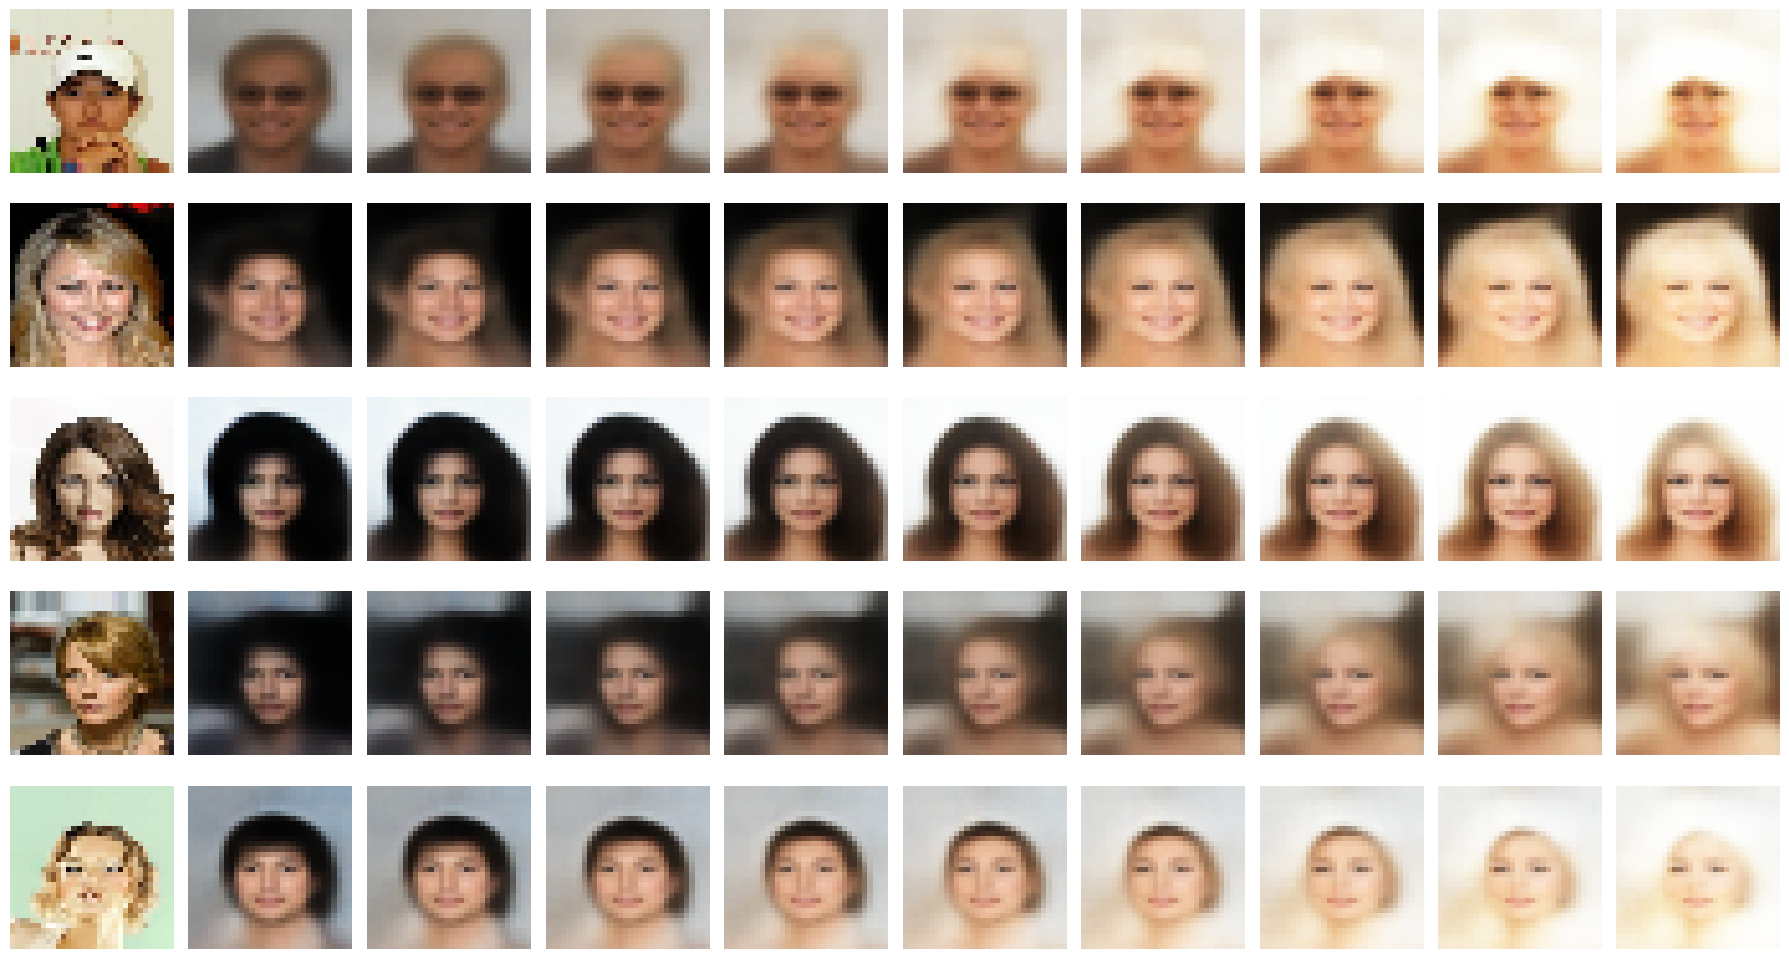

In [38]:
add_vector_to_images(labelled, vae, attribute_vec)

In [39]:
def morph_faces(data, vae):

    factors = np.arange(0, 1, 0.1)

    # Get two example images
    images, _ = list(data.take(1).get_single_element())
    images = images[:2]

    # Encode images into latent space
    _, _, z_points = vae.encoder.predict(images, verbose=0)

    fig = plt.figure(figsize=(18, 8))

    # Display first original image
    ax = fig.add_subplot(1, len(factors) + 2, 1)
    ax.axis("off")
    ax.imshow(images[0])

    # Generate interpolated faces
    for i, factor in enumerate(factors):

        # Linear interpolation in latent space
        changed_z = z_points[0] * (1 - factor) + z_points[1] * factor

        changed_image = vae.decoder.predict(
            np.array([changed_z]), verbose=0
        )[0]

        ax = fig.add_subplot(1, len(factors) + 2, i + 2)
        ax.axis("off")
        ax.imshow(changed_image)

    # Display second original image
    ax = fig.add_subplot(1, len(factors) + 2, len(factors) + 2)
    ax.axis("off")
    ax.imshow(images[1])

    plt.tight_layout()
    plt.show()

2026-11-05 02:10:06.081147: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'input_concatenate_fusion', 4 bytes spill stores, 8 bytes spill loads



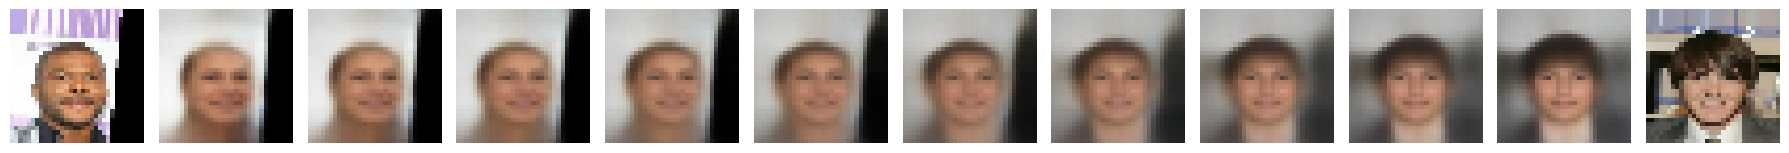

In [40]:
morph_faces(labelled, vae)